# 19. Mejores combinaciones, artefactos y dashboard

Este capítulo documenta cómo los modelos del libro llegan al producto. Cubre dos partes:
- **Del experimento a los artefactos:** la selección de la mejor combinación de cada modelo, su reentrenamiento con todo el entrenamiento, la serialización y la prueba de ida y vuelta;
- **Dashboard y despliegue:** la arquitectura del dashboard, sus decisiones de diseño, el despliegue en Render y la ficha del modelo.

| Sección | Contenido |
|---|---|
| 19.1 | Criterio de selección y tabla de las mejores combinaciones |
| 19.2 | Hiperparámetros finales |
| 19.3 | Reentrenamiento, serialización y metadatos |
| 19.4 | Prueba de ida y vuelta |
| 19.5 | Tamaño de los artefactos |
| 19.6 | Dashboard: arquitectura, contenido y decisiones de diseño |
| 19.7 | Despliegue en Render |
| 19.8 | Ficha del modelo |
| 19.9 | Síntesis del capítulo |
| 19.10 | Autoría, uso de herramientas y archivo del repositorio |

**Cómo se ejecuta.** El capítulo no entrena nada: lee lo que dejaron dos scripts en `artifacts/`. Para regenerarlo, desde la raíz del repositorio:

```
python experiments/entrenar_artefactos.py      # los 7 modelos base
python experiments/artefacto_des_cpl.py        # el modelo original
```

In [1]:
from config import *
from IPython.display import Image, Markdown, display

ARTEFACTOS = RAIZ / "artifacts"
seleccion = pd.read_csv(ARTEFACTOS / "mejores_combinaciones.csv")
metadatos = {ruta.name.replace(".metadata.json", ""): json.loads(ruta.read_text(encoding="utf-8"))
             for ruta in sorted(ARTEFACTOS.glob("*.metadata.json"))}
BASE = [m for m in seleccion["modelo"] if m != "des_cpl"]
print(f"Artefactos con metadatos: {len(metadatos)} ({', '.join(metadatos)})")

Artefactos con metadatos: 8 (arbol, bayes, des_cpl, knn, logistica, random_forest, svm, xgboost)


## 19.1. Criterio de selección

El experimento del capítulo 8 evaluó cada modelo con hasta 4 estrategias de balanceo y 4 optimizadores. El dashboard no las incluye todas: lleva **una combinación por modelo**, elegida con una regla fija y no por apreciación visual.

- **Mejor combinación de cada modelo.** La de mayor AUC-PR media en el bucle externo de la validación anidada, entre todas las combinaciones completadas de ese modelo (la regla del capítulo 11).
- **Mejor combinación global.** La de mayor AUC-PR media entre las siete elegidas.
- **Finalista.** Un modelo es finalista si su rango medio en los cinco folds externos dista del rango del mejor menos que la diferencia crítica de Nemenyi (capítulo 11). Se reporta además el valor p de Nemenyi frente al mejor.

La tabla la produce `seleccionar()` en `experiments/entrenar_artefactos.py` y queda en `artifacts/mejores_combinaciones.csv`, que es el archivo que lee la tabla de líderes del dashboard.

In [2]:
tabla_seleccion = pd.DataFrame({
    "modelo": seleccion["modelo"],
    "balanceo": seleccion["balanceo"],
    "optimizador": seleccion["optimizador"],
    "AUC-PR (media ± sd)": [f"{m:.4f} ± {s:.4f}" for m, s in zip(seleccion["auc_pr_media"], seleccion["auc_pr_sd"])],
    "AUC-ROC (media ± sd)": [f"{m:.4f} ± {s:.4f}" for m, s in zip(seleccion["auc_roc_media"], seleccion["auc_roc_sd"])],
    "combinaciones evaluadas": seleccion["combinaciones_evaluadas"],
    "rango medio": seleccion["rango_medio"],
    "p de Nemenyi vs. el mejor": seleccion["p_nemenyi_vs_mejor"].round(4),
    "finalista": seleccion["finalista"].map({True: "Sí", False: "No"}),
}).set_index("modelo")
display(tabla_seleccion)

with pd.option_context("display.max_colwidth", None):
    display(seleccion.set_index("modelo")[["motivo"]])

base = seleccion[seleccion["modelo"].isin(BASE)]
mejor = base.loc[base["auc_pr_media"].idxmax()]
print(f"Mejor combinación global: {mejor['modelo']} ({mejor['balanceo']} + {mejor['optimizador']}), "
      f"AUC-PR {mejor['auc_pr_media']:.4f} ± {mejor['auc_pr_sd']:.4f}; finalista: {bool(mejor['finalista'])}")
print("Finalistas:", ", ".join(base.loc[base["finalista"], "modelo"]))

,balanceo,optimizador,AUC-PR (media ± sd),AUC-ROC (media ± sd),combinaciones evaluadas,rango medio,p de Nemenyi vs. el mejor,finalista
modelo,,,,,,,,
xgboost,adasyn,random,0.2267 ± 0.0153,0.6689 ± 0.0066,16,1.6,1.0000,Sí
random_forest,ninguno,deap,0.2258 ± 0.0170,0.6703 ± 0.0087,16,1.6,1.0000,Sí
svm,ninguno,grid,0.2145 ± 0.0133,0.6626 ± 0.0080,16,2.8,0.9758,Sí
logistica,ninguno,optuna,0.2110 ± 0.0131,0.6619 ± 0.0079,16,4.0,0.5776,Sí
knn,ninguno,grid,0.2058 ± 0.0160,0.6504 ± 0.0105,12,5.2,0.1156,Sí
arbol,ninguno,grid,0.2034 ± 0.0106,0.6522 ± 0.0064,16,5.8,0.0345,No
bayes,ninguno,random,0.1995 ± 0.0115,0.6479 ± 0.0100,16,7.0,0.0015,No
des_cpl,por modelo base,optuna,0.2279 ± 0.0174,0.6721 ± 0.0086,60,NaN,NaN,Sí


,motivo
modelo,
xgboost,Mayor AUC-PR media del bucle externo entre sus 16 combinaciones; la segunda (smote + random) queda a 0.0001
random_forest,Mayor AUC-PR media del bucle externo entre sus 16 combinaciones; la segunda (ninguno + grid) queda a 0.0014
svm,Mayor AUC-PR media del bucle externo entre sus 16 combinaciones; la segunda (ninguno + random) queda a 0.0001
logistica,Mayor AUC-PR media del bucle externo entre sus 16 combinaciones; la segunda (ninguno + deap) queda a 0.0001
knn,Mayor AUC-PR media del bucle externo entre sus 12 combinaciones; la segunda (ninguno + random) queda a 0.0006
arbol,Mayor AUC-PR media del bucle externo entre sus 16 combinaciones; la segunda (class_weight + random) queda a 0.0001
bayes,Mayor AUC-PR media del bucle externo entre sus 16 combinaciones; la segunda (class_weight + random) queda a 0.0001
des_cpl,"Modelo original del Entregable 3. Combina árbol, Random Forest, XGBoost y SVM; Nemenyi no lo separa del mejor benchmark (capítulo 13)"


Mejor combinación global: xgboost (adasyn + random), AUC-PR 0.2267 ± 0.0153; finalista: True
Finalistas: xgboost, random_forest, svm, logistica, knn


**Lectura.**
- **La mejor combinación global es XGBoost con ADASYN y Random Search** (AUC-PR de 0.2267 ± 0.0153), y pertenece al conjunto de finalistas.
- **Cinco de los siete modelos son finalistas.** Nemenyi no distingue de XGBoost a Random Forest, SVM, regresión logística ni k-NN; el árbol y Naive Bayes sí quedan separados. Con cinco folds la prueba tiene poca potencia, y por eso el conjunto de finalistas es amplio (capítulo 11).
- **Las diferencias dentro de cada modelo son mínimas.** En seis de los siete modelos, la segunda mejor combinación queda a 0.0001 o 0.0006 de la primera; solo en Random Forest la distancia llega a 0.0014. El balanceo y el optimizador importan mucho menos que la familia del modelo, la misma conclusión del capítulo 9.
- **k-NN tiene 12 combinaciones y no 16,** porque no admite `class_weight`.
- **La fila de DES-CPL no se compara de igual a igual.** Sus cifras son las del protocolo, con 60 evaluaciones, y las de los siete modelos son las del experimento original, con 8 a 12. Con el mismo presupuesto, XGBoost obtiene 0.2290 frente a 0.2279 de DES-CPL (sección 13.5). El dashboard lo indica en la columna «Presupuesto» y en una nota bajo la tabla.

## 19.2. Hiperparámetros finales

La validación anidada elige una configuración de hiperparámetros en cada fold externo, así que para el modelo final hay que quedarse con una. La regla es la del capítulo 10: la **configuración modal**, es decir, la que más folds eligieron. La columna «criterio» dice en cuántos de los cinco folds se eligió.

In [3]:
filas = []
for modelo in BASE:
    m = metadatos[modelo]
    filas.append({"modelo": modelo, "criterio": m["hiperparametros_criterio"],
                  "hiperparámetros": ", ".join(f"{k.replace('modelo__', '')} = {v:.4g}" if isinstance(v, float)
                                               else f"{k.replace('modelo__', '')} = {v}"
                                               for k, v in m["hiperparametros"].items())})
with pd.option_context("display.max_colwidth", None):
    display(pd.DataFrame(filas).set_index("modelo"))

d = metadatos["des_cpl"]
print("DES-CPL:", d["hiperparametros"])
print("  criterio:", d["hiperparametros_criterio"])
print("  modelos que combina:", ", ".join(d["modelos_base"]))

,criterio,hiperparámetros
modelo,,
xgboost,Configuración modal: elegida en 1 de 5 folds externos,"colsample_bytree = 0.9759, learning_rate = 0.04201, max_depth = 10, min_child_weight = 1.016, subsample = 0.6545"
random_forest,Configuración modal: elegida en 1 de 5 folds externos,"max_depth = 18, max_features = 0.1967, min_samples_leaf = 9, n_estimators = 447"
svm,Configuración modal: elegida en 5 de 5 folds externos,estimator__C = 0.003511
logistica,Configuración modal: elegida en 1 de 5 folds externos,"C = 0.1175, penalty = l1"
knn,Configuración modal: elegida en 5 de 5 folds externos,"n_neighbors = 201, weights = distance"
arbol,Configuración modal: elegida en 3 de 5 folds externos,"criterion = entropy, max_depth = 8, min_samples_leaf = 100"
bayes,Configuración modal: elegida en 1 de 5 folds externos,var_smoothing = 0.01176


DES-CPL: {'k': 20, 'tau': 0.0003, 'encogimiento': 0.9, 'n_pliegues': 3, 'competencia': 'brier', 'ponderacion': 'prevalencia', 'poda': 4}
  criterio: Búsqueda bayesiana (Optuna, TPE) de 60 evaluaciones sobre el conjunto de selección del entrenamiento completo (sección 13.8)
  modelos que combina: arbol, random_forest, xgboost, svm


**Lectura y una limitación de la regla.**
- En k-NN y SVM los cinco folds eligieron la misma configuración, y en el árbol, tres: ahí la moda es informativa.
- En XGBoost, Random Forest, la regresión logística y Naive Bayes **cada fold eligió una configuración distinta**. Sus espacios son continuos y los optimizadores casi nunca repiten un punto, así que no hay moda y la regla se queda con la configuración del primer fold. Es una elección arbitraria entre cinco candidatas equivalentes: el capítulo 12 mostró que, en estos modelos, las diferencias entre configuraciones buenas son menores que la variación entre folds.
- DES-CPL no usa esta regla. Sus modelos base llevan la configuración que eligió Random Search con 60 evaluaciones sobre todo el entrenamiento, y sus hiperparámetros propios ($k$, $\tau$, $\lambda$ y la poda) salen de la búsqueda de 60 evaluaciones de la sección 13.8.

## 19.3. Reentrenamiento, serialización y metadatos

Con los hiperparámetros fijados, cada modelo se reentrena **con todo el conjunto de entrenamiento** (79 473 encuentros de 56 036 pacientes) y se guarda el **pipeline completo**: preprocesamiento, balanceo y modelo. Así el dashboard recibe las 38 variables originales y no necesita repetir ninguna transformación.

- **Formato.** `joblib` con `compress=3`, en `artifacts/<modelo>.joblib`.
- **El dashboard no entrena ni optimiza.** Solo carga estos archivos.
- **Metadatos.** Junto a cada modelo hay un `<modelo>.metadata.json`. La celda siguiente comprueba que todos traen lo necesario para usar y auditar el modelo: versiones de las librerías, semilla, hiperparámetros finales, esquema de las columnas de entrada (nombre, tipo y rango o niveles válidos) y métricas del bucle externo.

In [4]:
EXIGIDO = ["versiones", "semilla", "hiperparametros", "esquema", "metricas_bucle_externo"]
filas = []
for modelo, m in metadatos.items():
    filas.append({"modelo": modelo,
                  "campos exigidos": "completos" if all(c in m for c in EXIGIDO) else "FALTAN",
                  "semilla": m["semilla"],
                  "columnas en el esquema": len(m["esquema"]),
                  "scikit-learn": m["versiones"]["scikit-learn"],
                  "python": m["versiones"]["python"],
                  "AUC-PR bucle externo": round(m["metricas_bucle_externo"]["auc_pr"]["media"], 4),
                  "AUC-PR prueba": round(m["metricas_prueba"]["auc_pr"], 4)})
display(pd.DataFrame(filas).set_index("modelo"))

ejemplo = metadatos["xgboost"]["esquema"]
print("Ejemplo del esquema (XGBoost):")
for columna in list(ejemplo)[:2] + list(ejemplo)[-1:]:
    print(f"  {columna}: {ejemplo[columna]}")

,campos exigidos,semilla,columnas en el esquema,scikit-learn,python,AUC-PR bucle externo,AUC-PR prueba
modelo,,,,,,,
arbol,completos,42,38,1.9.1,3.12.13,0.2034,0.2083
bayes,completos,42,38,1.9.1,3.12.13,0.1995,0.1943
des_cpl,completos,42,38,1.9.1,3.12.13,0.2279,0.2293
knn,completos,42,38,1.9.1,3.12.13,0.2058,0.2060
logistica,completos,42,38,1.9.1,3.12.13,0.2110,0.2141
random_forest,completos,42,38,1.9.1,3.12.13,0.2258,0.2279
svm,completos,42,38,1.9.1,3.12.13,0.2145,0.2157
xgboost,completos,42,38,1.9.1,3.12.13,0.2267,0.2315


Ejemplo del esquema (XGBoost):
  time_in_hospital: {'tipo': 'numerica', 'entero': True, 'min': 1.0, 'max': 14.0, 'mediana': 4.0}
  num_lab_procedures: {'tipo': 'numerica', 'entero': True, 'min': 1.0, 'max': 132.0, 'mediana': 44.0}
  tolazamide: {'tipo': 'categorica', 'niveles': ['No', 'Steady', 'Cambio'], 'moda': 'No'}


El esquema es lo que usa el formulario de predicción del dashboard: de él salen los campos, sus rangos válidos y los niveles de cada variable categórica, de modo que el formulario no puede pedir un valor que el modelo no conozca.

El AUC-PR de prueba de XGBoost en esta tabla (0.2315) es el del artefacto, reentrenado para el dashboard. El ajuste del capítulo 10 obtuvo 0.2285. No se investigó el origen de esa diferencia de 0.003; es del orden de la variación de XGBoost entre semillas que midió la sección 16.4 (rango de 0.0068). Random Forest sí coincide con el capítulo 10 (0.2279).

## 19.4. Prueba de ida y vuelta

Un modelo serializado solo sirve si predice lo mismo que el modelo en memoria. Al guardar cada artefacto, el script lo vuelve a cargar del disco y compara sus probabilidades con las del modelo en memoria sobre **todo el conjunto de prueba** (19 867 encuentros). Si la diferencia máxima supera $10^{-9}$, el script se detiene y no escribe los metadatos.

In [5]:
filas = []
for modelo, m in metadatos.items():
    diferencia = m.get("ida_y_vuelta_diferencia_max")
    filas.append({"modelo": modelo,
                  "ida y vuelta": "Aprobada" if m["ida_y_vuelta"] else "FALLA",
                  "diferencia máxima": "no registrada" if diferencia is None else f"{diferencia:.1e}",
                  "tamaño (MB)": round(m["tamano_mb"], 3),
                  "ajuste (s)": round(m["tiempo_ajuste_s"], 1),
                  "inferencia (ms por caso)": round(m["tiempo_inferencia_ms_por_caso"], 3)})
ida_vuelta = pd.DataFrame(filas).set_index("modelo")
display(ida_vuelta)
print(f"Aprobadas: {(ida_vuelta['ida y vuelta'] == 'Aprobada').sum()} de {len(ida_vuelta)}")
print(f"Tamaño total de los modelos: {ida_vuelta['tamaño (MB)'].sum():.1f} MB")
if "diferencia_con_seccion_13_8" in metadatos["des_cpl"]:
    print(f"DES-CPL, diferencia máxima con las predicciones de la sección 13.8: "
          f"{metadatos['des_cpl']['diferencia_con_seccion_13_8']:.1e}")

,ida y vuelta,diferencia máxima,tamaño (MB),ajuste (s),inferencia (ms por caso)
modelo,,,,,
arbol,Aprobada,0.0e+00,0.011,9.4,0.024
bayes,Aprobada,0.0e+00,0.008,7.5,0.028
des_cpl,Aprobada,1.1e-16,12.909,407.2,0.453
knn,Aprobada,0.0e+00,4.802,6.6,0.825
logistica,Aprobada,0.0e+00,0.004,10.9,0.021
random_forest,Aprobada,1.1e-16,30.134,84.9,0.051
svm,Aprobada,0.0e+00,0.008,9.2,0.020
xgboost,Aprobada,no registrada,1.205,92.3,0.034


Aprobadas: 8 de 8
Tamaño total de los modelos: 49.1 MB
DES-CPL, diferencia máxima con las predicciones de la sección 13.8: 5.0e-09


**Lectura.** Los ocho artefactos aprueban. Donde se registró, la diferencia máxima es del orden de $10^{-16}$, la precisión de la máquina. Para DES-CPL hay una comprobación adicional: el artefacto reproduce las predicciones de la evaluación en prueba de la sección 13.8 con una diferencia de $5 \cdot 10^{-9}$, así que el modelo del dashboard es el mismo que se evaluó en el libro.

## 19.5. Tamaño de los artefactos

El tamaño importa por dos límites: GitHub rechaza archivos de más de 100 MB y el plan gratuito de Render tiene 512 MB de memoria.

- **Random Forest es el más pesado (30.1 MB con compresión).** Son 447 árboles de profundidad hasta 18. No se redujo el número de árboles porque el archivo cabe con holgura en el límite de GitHub y cambiarlo habría alterado el modelo evaluado en el libro.
- **DES-CPL ocupa 12.9 MB.** Guarda 16 modelos (4 finales y 12 de pliegue) y el conjunto de selección completo, que necesita para buscar vecinos.
- **k-NN ocupa 4.8 MB,** porque guarda el entrenamiento transformado.
- **Los demás pesan menos de 1.3 MB.**

Los ocho suman unos 49 MB en disco. En memoria ocupan más, y por eso el dashboard no los carga todos a la vez (sección 19.6.3).

## 19.6. Dashboard

**URL pública:** [https://readmision-diabetes.onrender.com](https://readmision-diabetes.onrender.com)

### 19.6.1. Arquitectura

Es una aplicación Dash multipágina (`use_pages=True`) que separa la interfaz, la lógica de datos y los artefactos.

| Pieza | Archivo | Qué hace |
|---|---|---|
| Punto de entrada | `app.py` | Crea la aplicación, la barra de navegación y el pie; expone `server` para gunicorn |
| Páginas | `pages/portada.py`, `contexto.py`, `eda.py`, `modelos.py` | Una por sección, cada una con sus *callbacks* |
| Datos | `src/tablero/datos.py` | Única puerta a los datos y a los artefactos, con caché |
| Figuras | `src/tablero/graficos.py`, `graficos_clinicos.py` | Funciones que devuelven la figura y su lectura calculada |
| Inferencia | `src/tablero/inferencia.py` | Carga de modelos, validación del formulario, predicción y explicación local |
| Análisis | `src/tablero/analitica.py` | Predicción conforme, comparación estadística, equidad y pacientes parecidos |
| Explicación | `src/explicacion.py` | Valores de Shapley por permutaciones sobre las variables originales |
| Presentación | `src/tablero/config.py`, `tema.py`, `formato.py`, `componentes.py` | Textos, paleta y plantilla de Plotly, formato de cifras y componentes reutilizables |
| Estilo | `assets/` | Hoja de estilos, tema claro y oscuro e interacción |
| Artefactos | `artifacts/` | Modelos, metadatos, predicciones de prueba y valores SHAP precalculados |

### 19.6.2. Contenido

- **Portada (`/`).** Presentación del problema y acceso a las tres secciones.
- **Contexto (`/contexto`).** El problema con sus cifras y su fuente, la pregunta de investigación y los objetivos, la descripción de los datos con su licencia y el diccionario de variables, el diagrama de la metodología, las limitaciones, la ética y los autores.
- **EDA (`/eda`).** Filtros globales que actualizan todos los gráficos, la distribución del objetivo, las distribuciones univariadas, un explorador bivariado con ejes y color elegibles, la matriz de correlación, los faltantes y los atípicos. Cada gráfico lleva una lectura que se calcula con los datos filtrados.
- **Modelos (`/modelos`).** Nueve subpestañas:

| Subpestaña | Contenido |
|---|---|
| Tabla de líderes | Las mejores combinaciones de la sección 19.1, con orden y filtro por columna |
| Capacidad del servicio | Cuántas readmisiones se detectan según cuántos pacientes puede atender el equipo |
| Predicción en vivo | Formulario generado desde el esquema, probabilidad, conjunto de predicción conforme con su cobertura, explicación SHAP local, «¿qué pasaría si...?», pacientes parecidos y consenso de los modelos |
| Diagnóstico | Matriz de confusión, curvas ROC y de precisión-recall, y calibración del modelo elegido |
| Interpretabilidad | Resumen SHAP global del modelo elegido |
| Comparación estadística | Friedman y diagrama de diferencia crítica de Nemenyi con el modelo original incluido |
| Equidad | Desempeño y detección por subgrupo |
| Modelo original | Descripción y algoritmo de DES-CPL, pruebas de hipótesis con valores p ajustados y veredicto |
| Ficha del modelo | El contenido de `MODEL_CARD.md` |

### 19.6.3. Decisiones de diseño

- **Una combinación por modelo, no las 112.** La tabla de líderes muestra las elegidas en la sección 19.1.
- **Dos presupuestos, declarados.** La tabla de líderes conserva las cifras del experimento original y marca el presupuesto de cada fila. La comparación estadística usa la matriz del protocolo, con todos los modelos a 60 evaluaciones, más LightGBM y CatBoost: la misma de la sección 13.5.
- **El umbral es operativo, no 0.5.** Se marca al 15 % de mayor riesgo, la regla del capítulo 10; con 0.5 los modelos no señalan a casi nadie.
- **Explicación sobre las variables originales.** Los valores de Shapley se calculan sobre las 38 variables que ve el usuario, no sobre las columnas codificadas, con 6 permutaciones y 20 pacientes de referencia en la predicción en vivo. La implementación es propia (`src/explicacion.py`) y cumple la propiedad de eficiencia, que verifican las pruebas.
- **Incertidumbre junto a la predicción.** El conjunto de predicción conforme se muestra como un semáforo con su cobertura nominal y la verificada. Aquí los cuantiles se calibran con una mitad del conjunto de prueba y se verifican en la otra, por lo que la cobertura no coincide con la de la sección 13.8.
- **Memoria.** Los datos y los metadatos se cargan una sola vez al arrancar. Los modelos se cargan cuando se piden y se mantienen como mucho dos en memoria. El servidor usa un solo proceso con cuatro hilos, porque cada proceso adicional duplicaría los datos y los modelos.
- **Robustez.** El formulario valida tipos y rangos con el esquema de cada modelo y responde con un aviso, sin detener la aplicación. Si falta un artefacto, la sección lo dice en lugar de fallar.
- **Diseño visual.** Tema de `dash-bootstrap-components`, una tipografía, la misma plantilla de Plotly en todas las figuras, modo claro y oscuro, y azul para «no readmitido» y ámbar para «readmitido», siempre acompañados de un rótulo para no depender solo del color.
- **Lenguaje.** Las cifras del dashboard usan coma decimal y nombres legibles de los modelos, porque se dirige a un lector no técnico; el libro conserva el punto decimal.

### 19.6.4. Capturas de pantalla

La celda muestra las capturas guardadas en `docs/capturas/` e indica cuáles faltan.

**Portada**

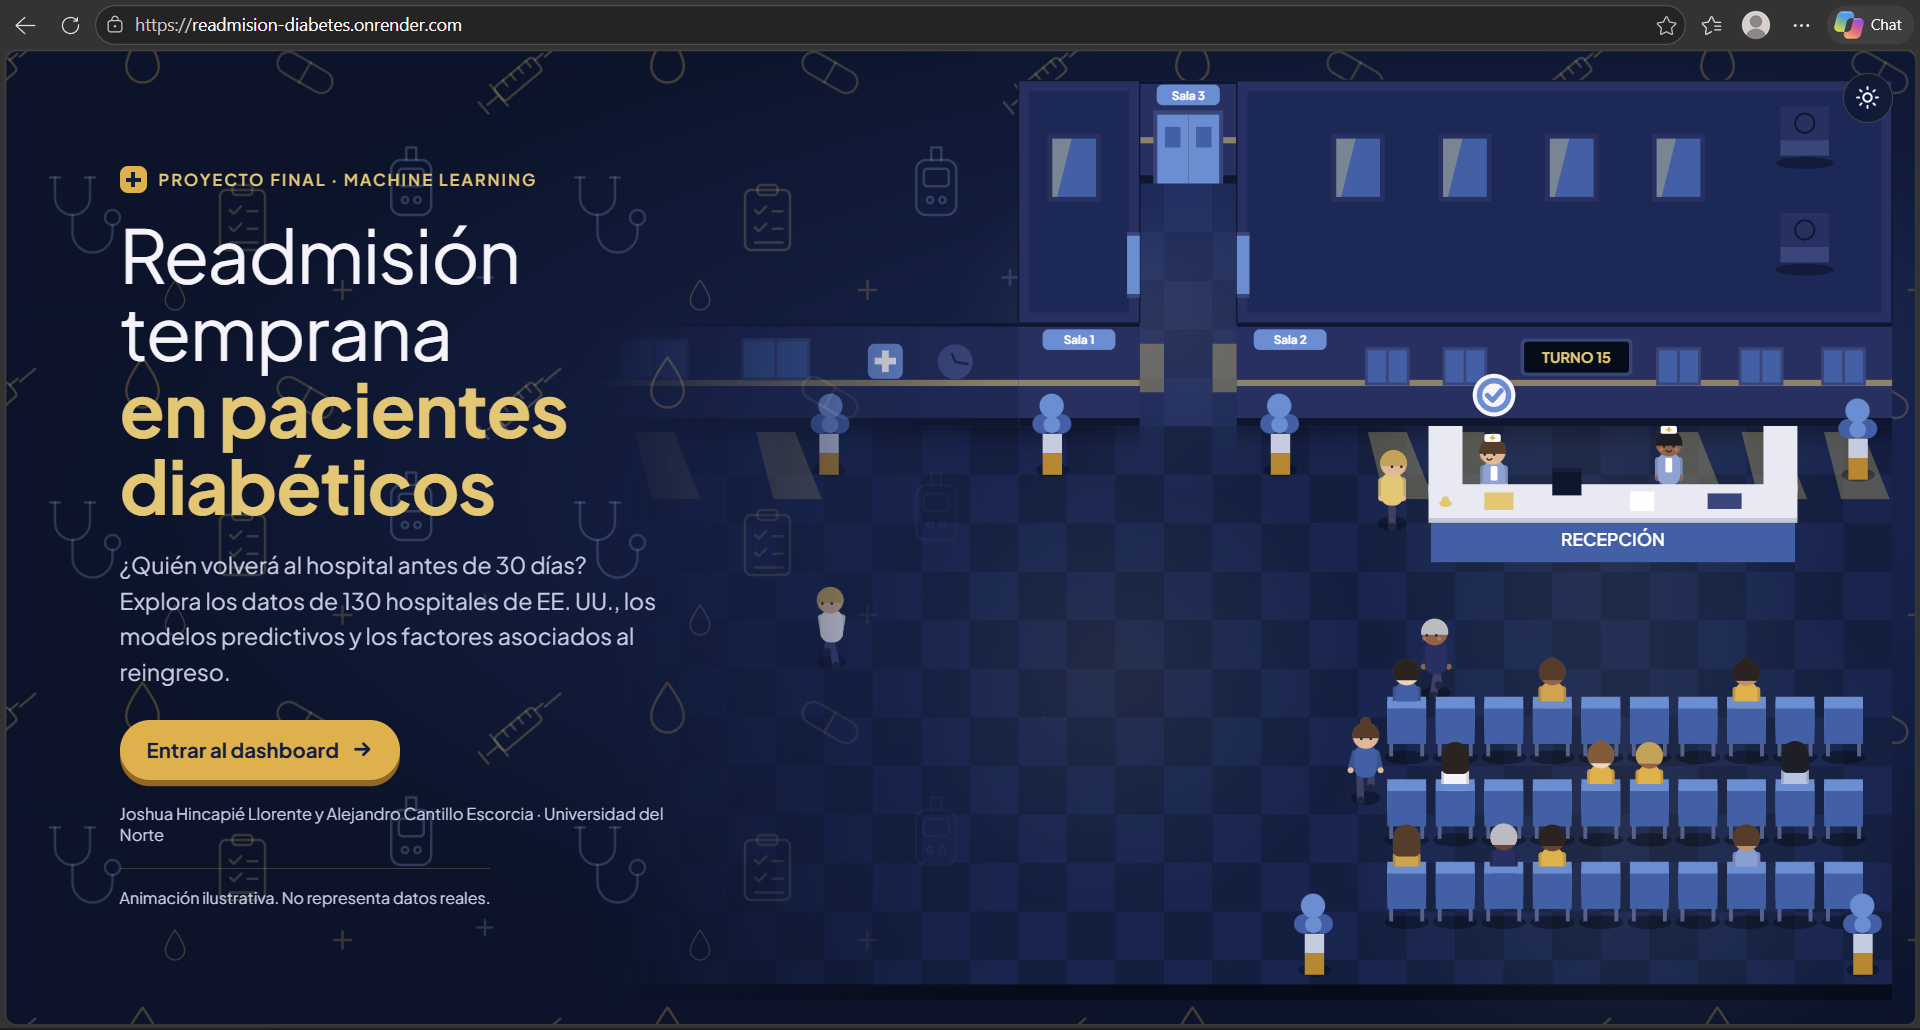

**Sección 1: Contexto**

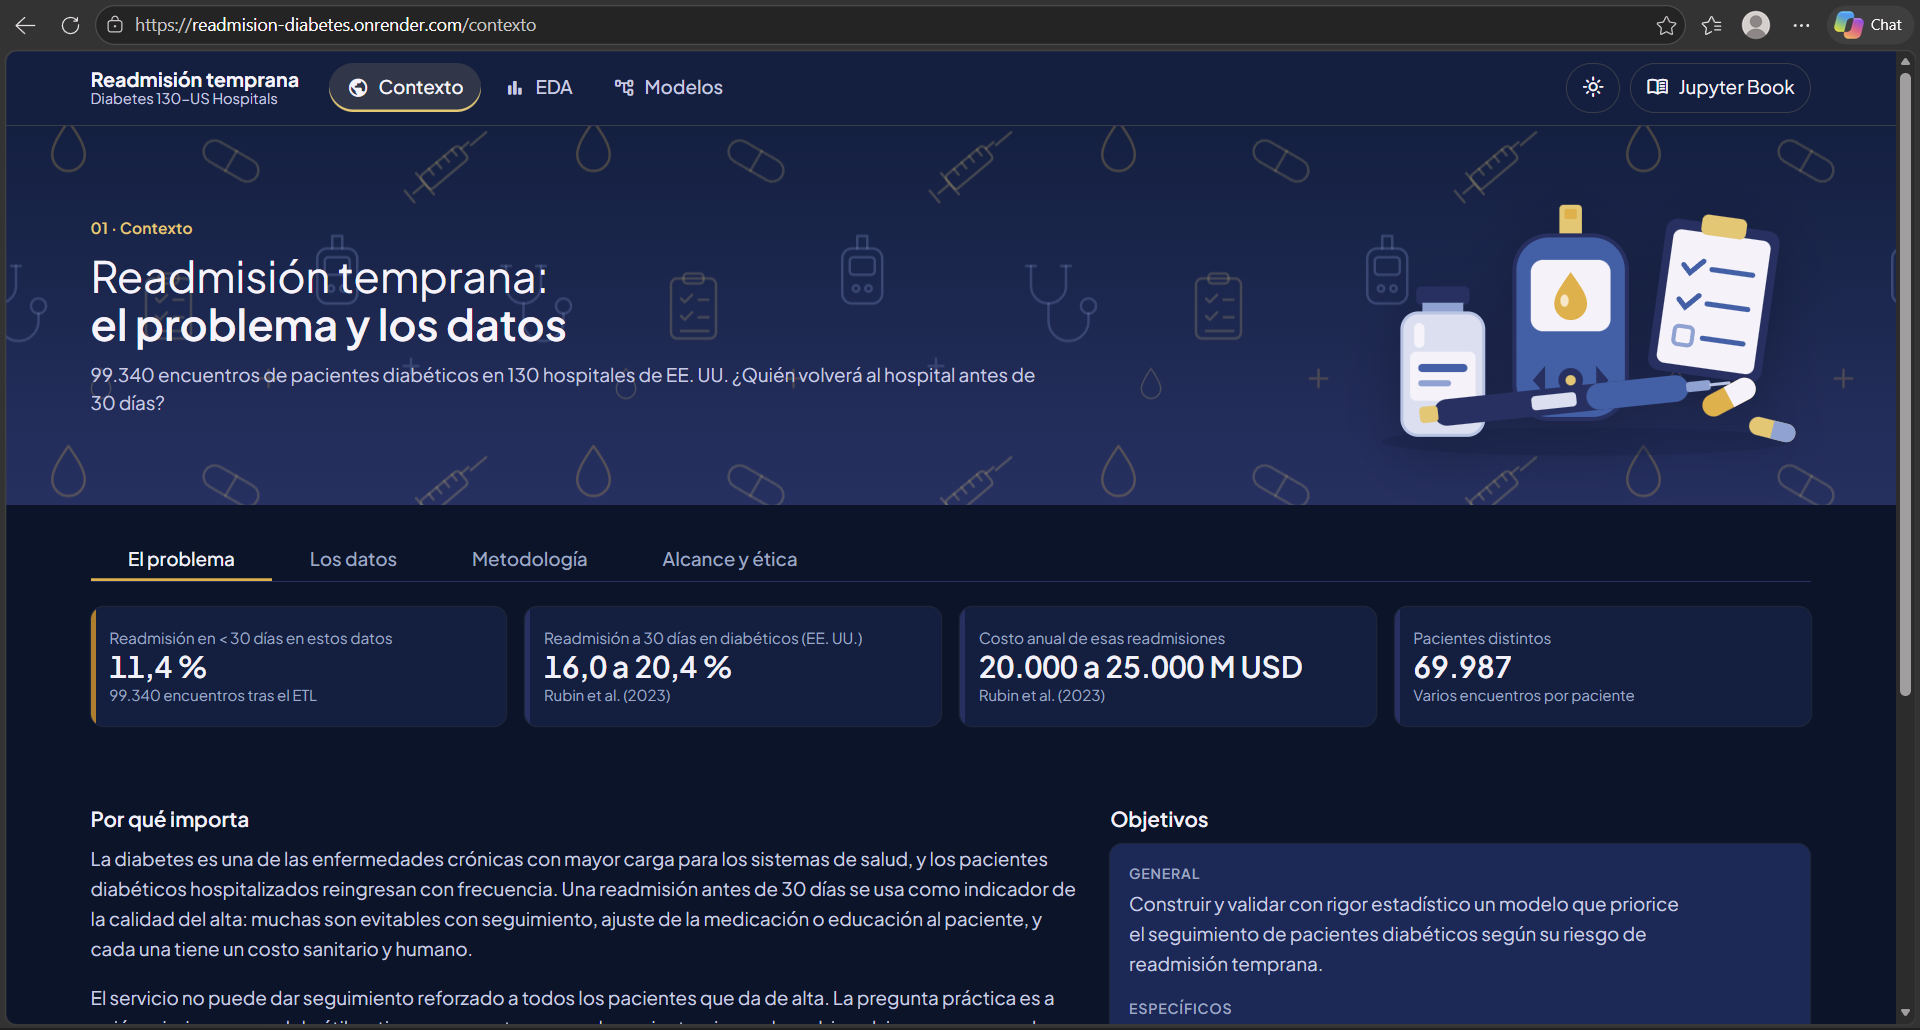

**Sección 2: EDA, con los filtros globales**

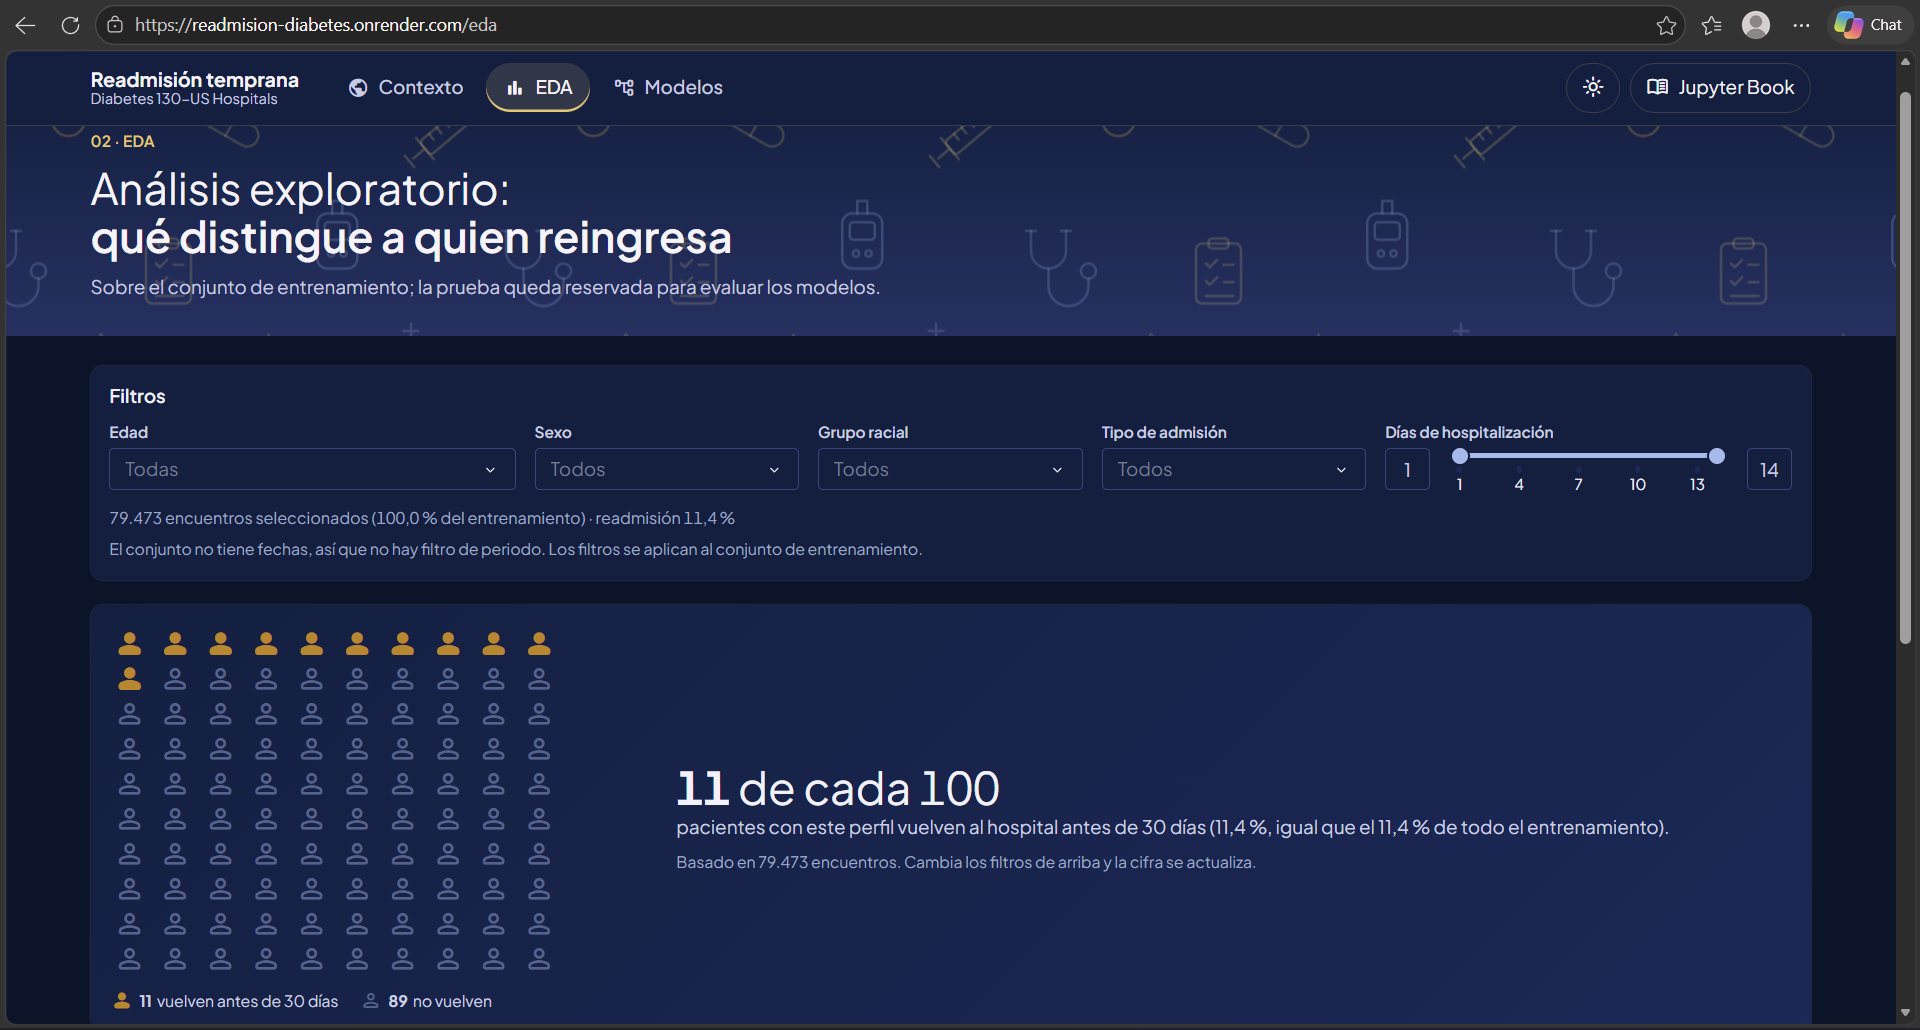

**Sección 3: tabla de líderes**

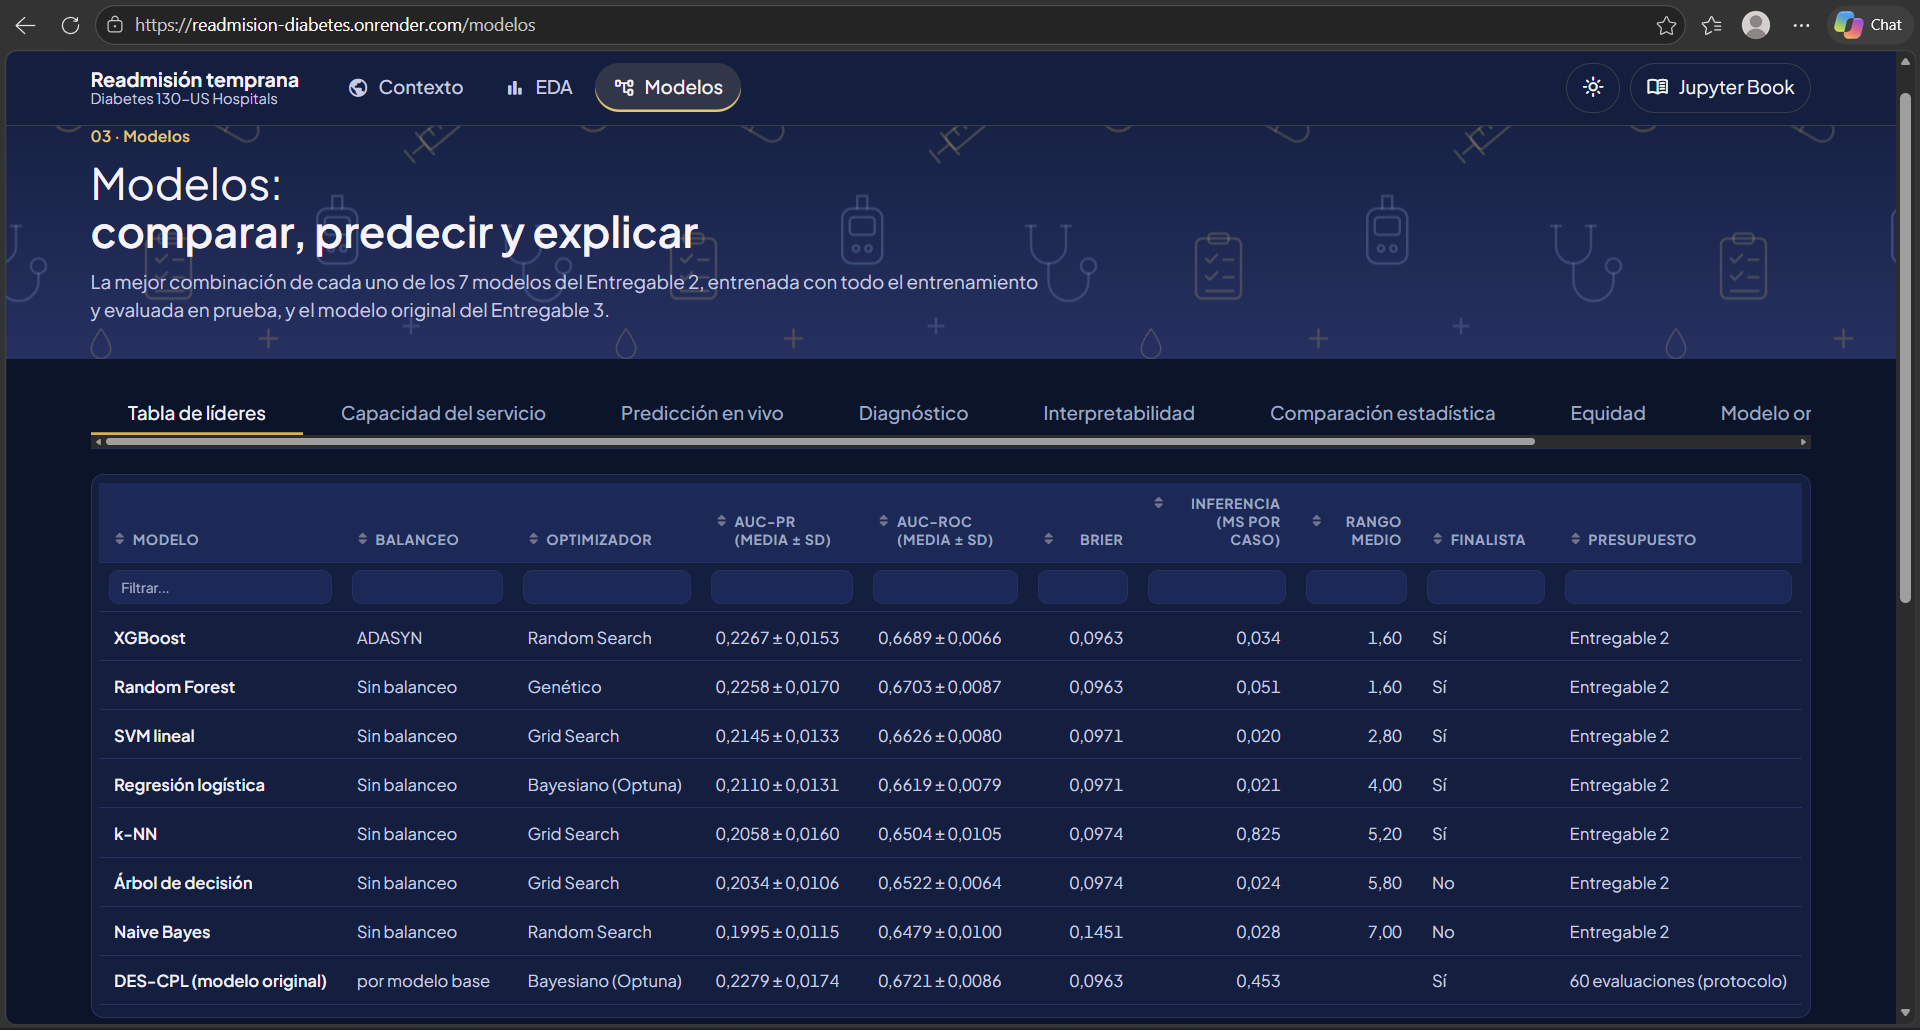

**Sección 3: predicción en vivo con explicación local e incertidumbre**

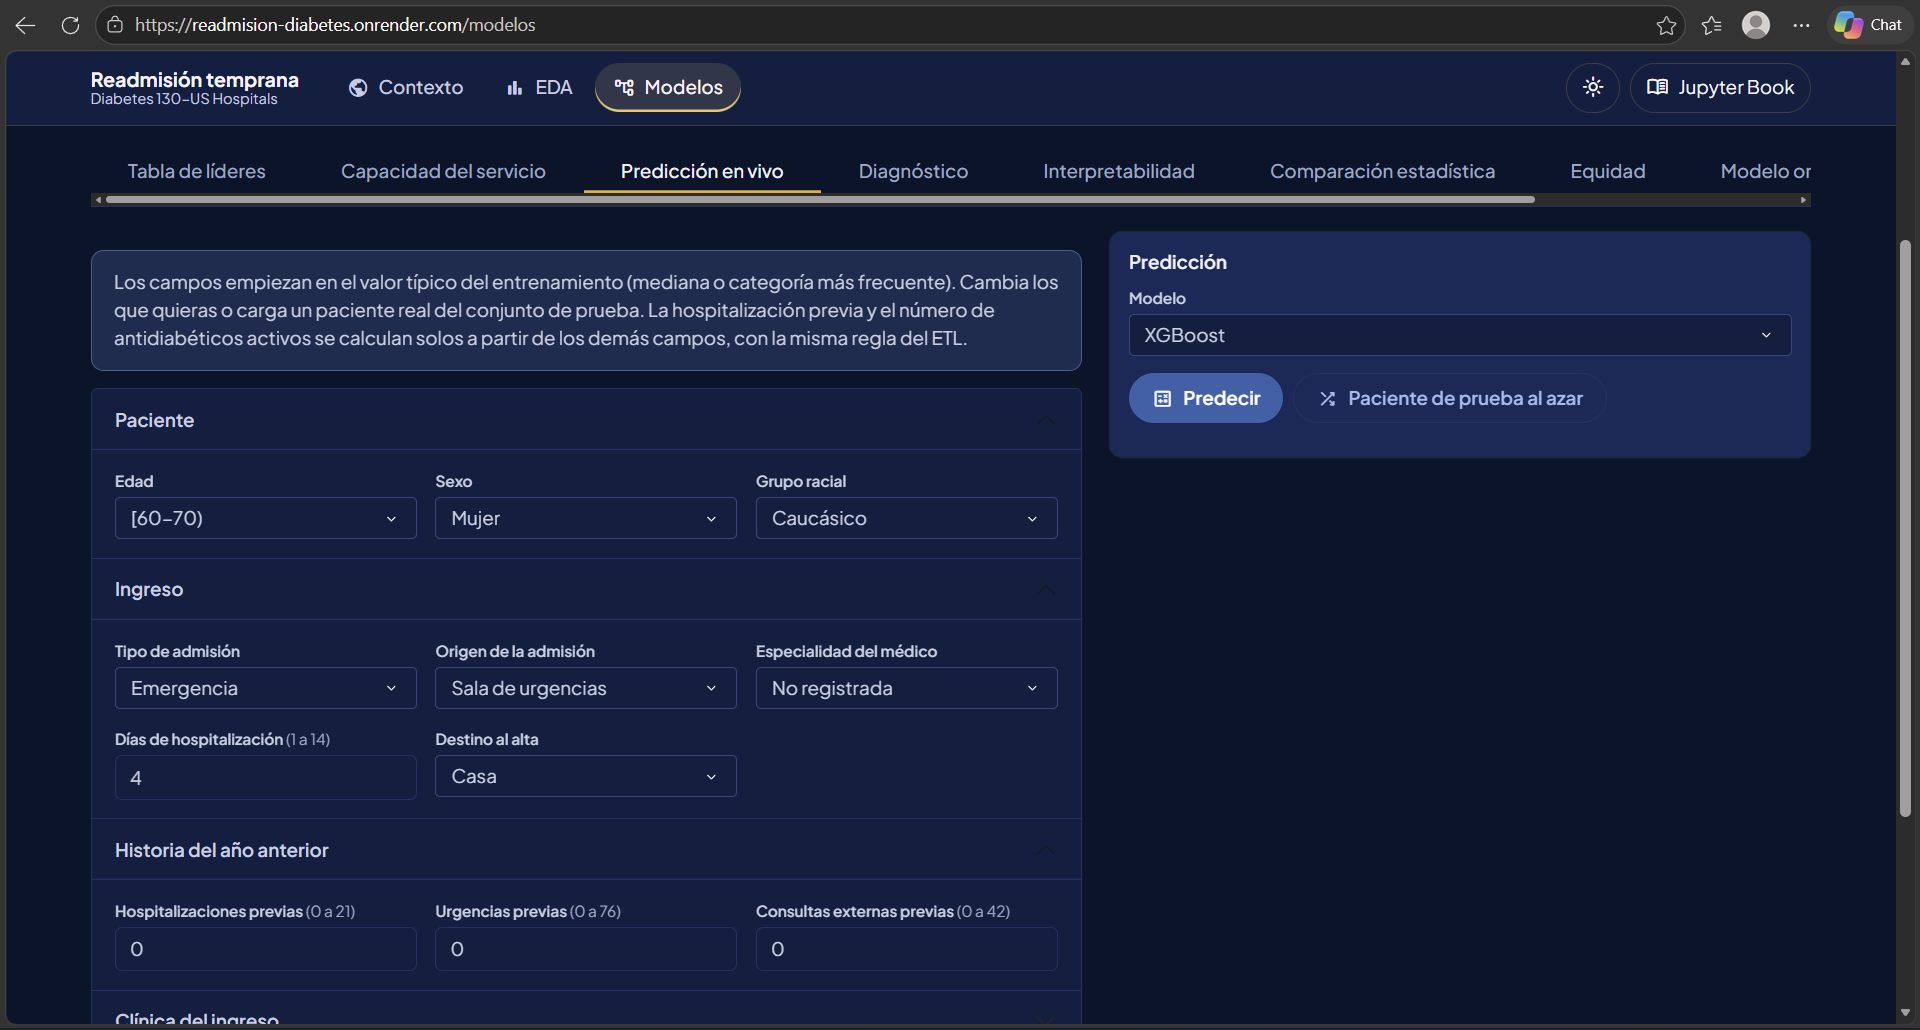

**Sección 3: comparación estadística con el modelo original**

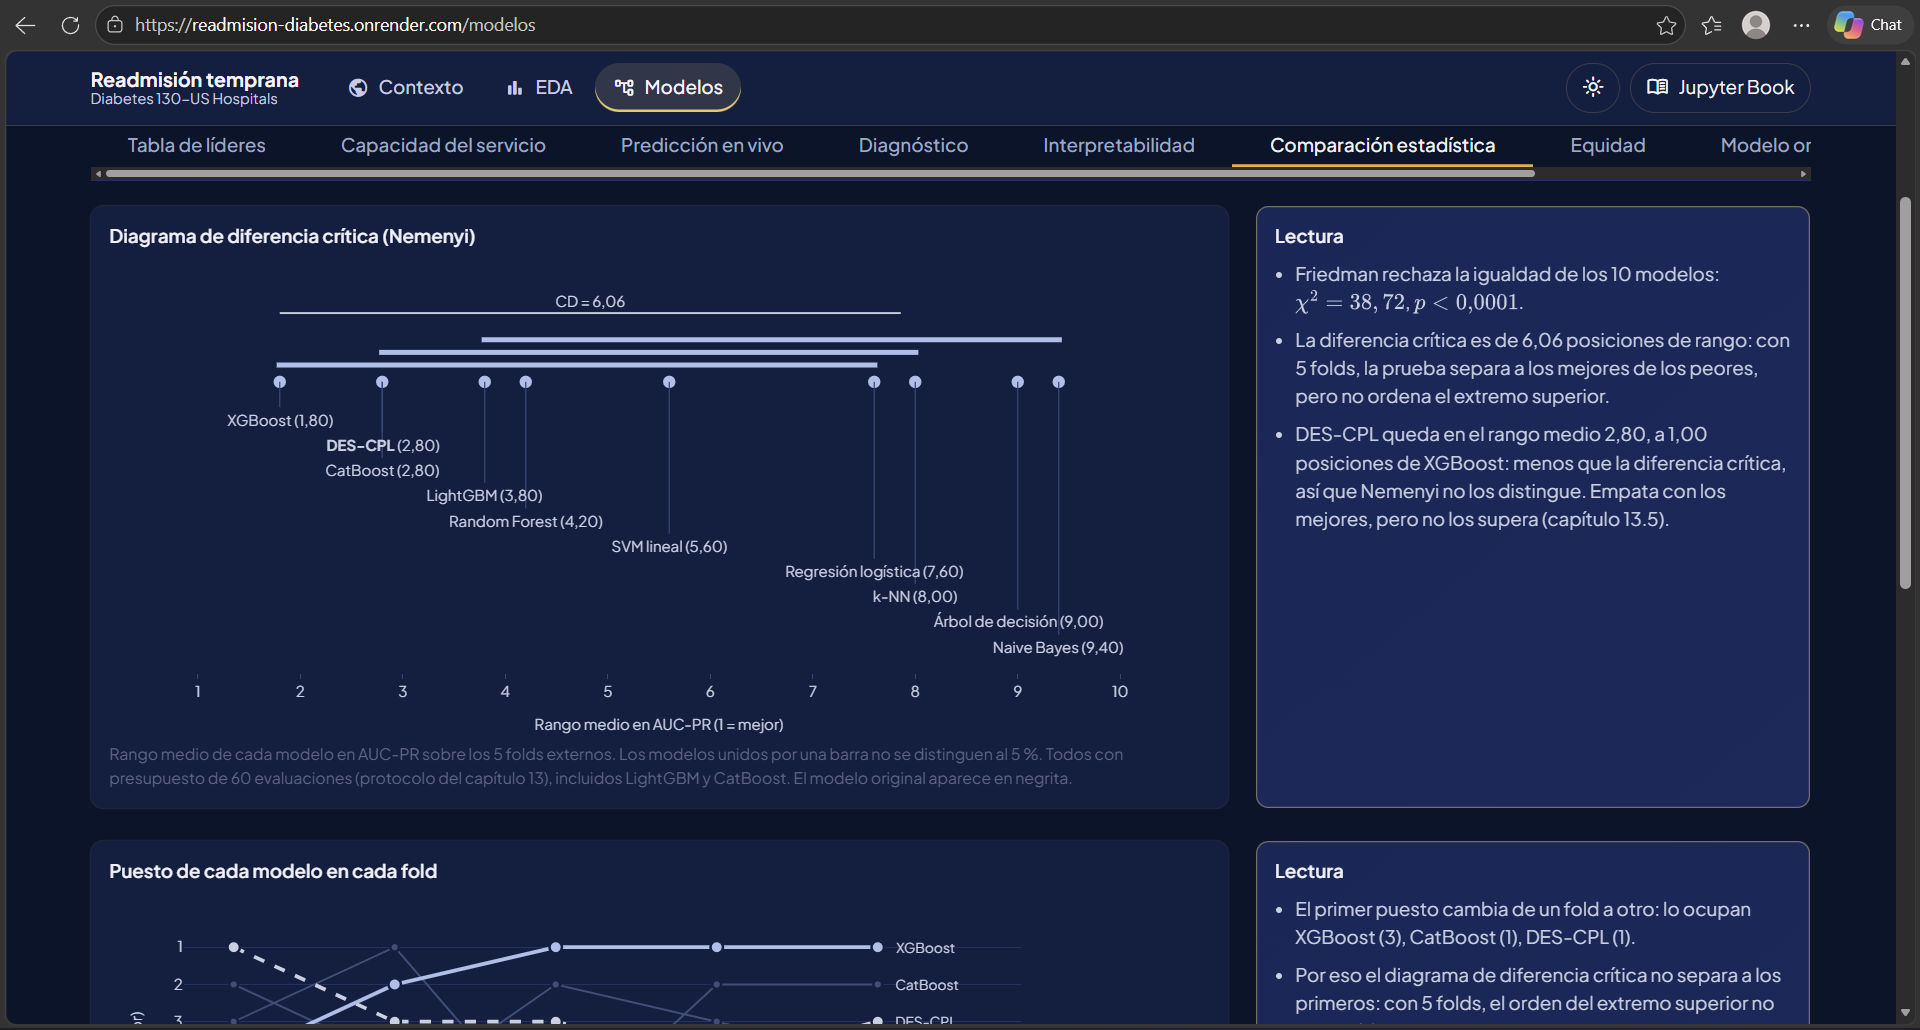

**Sección 3: modelo original y veredicto**

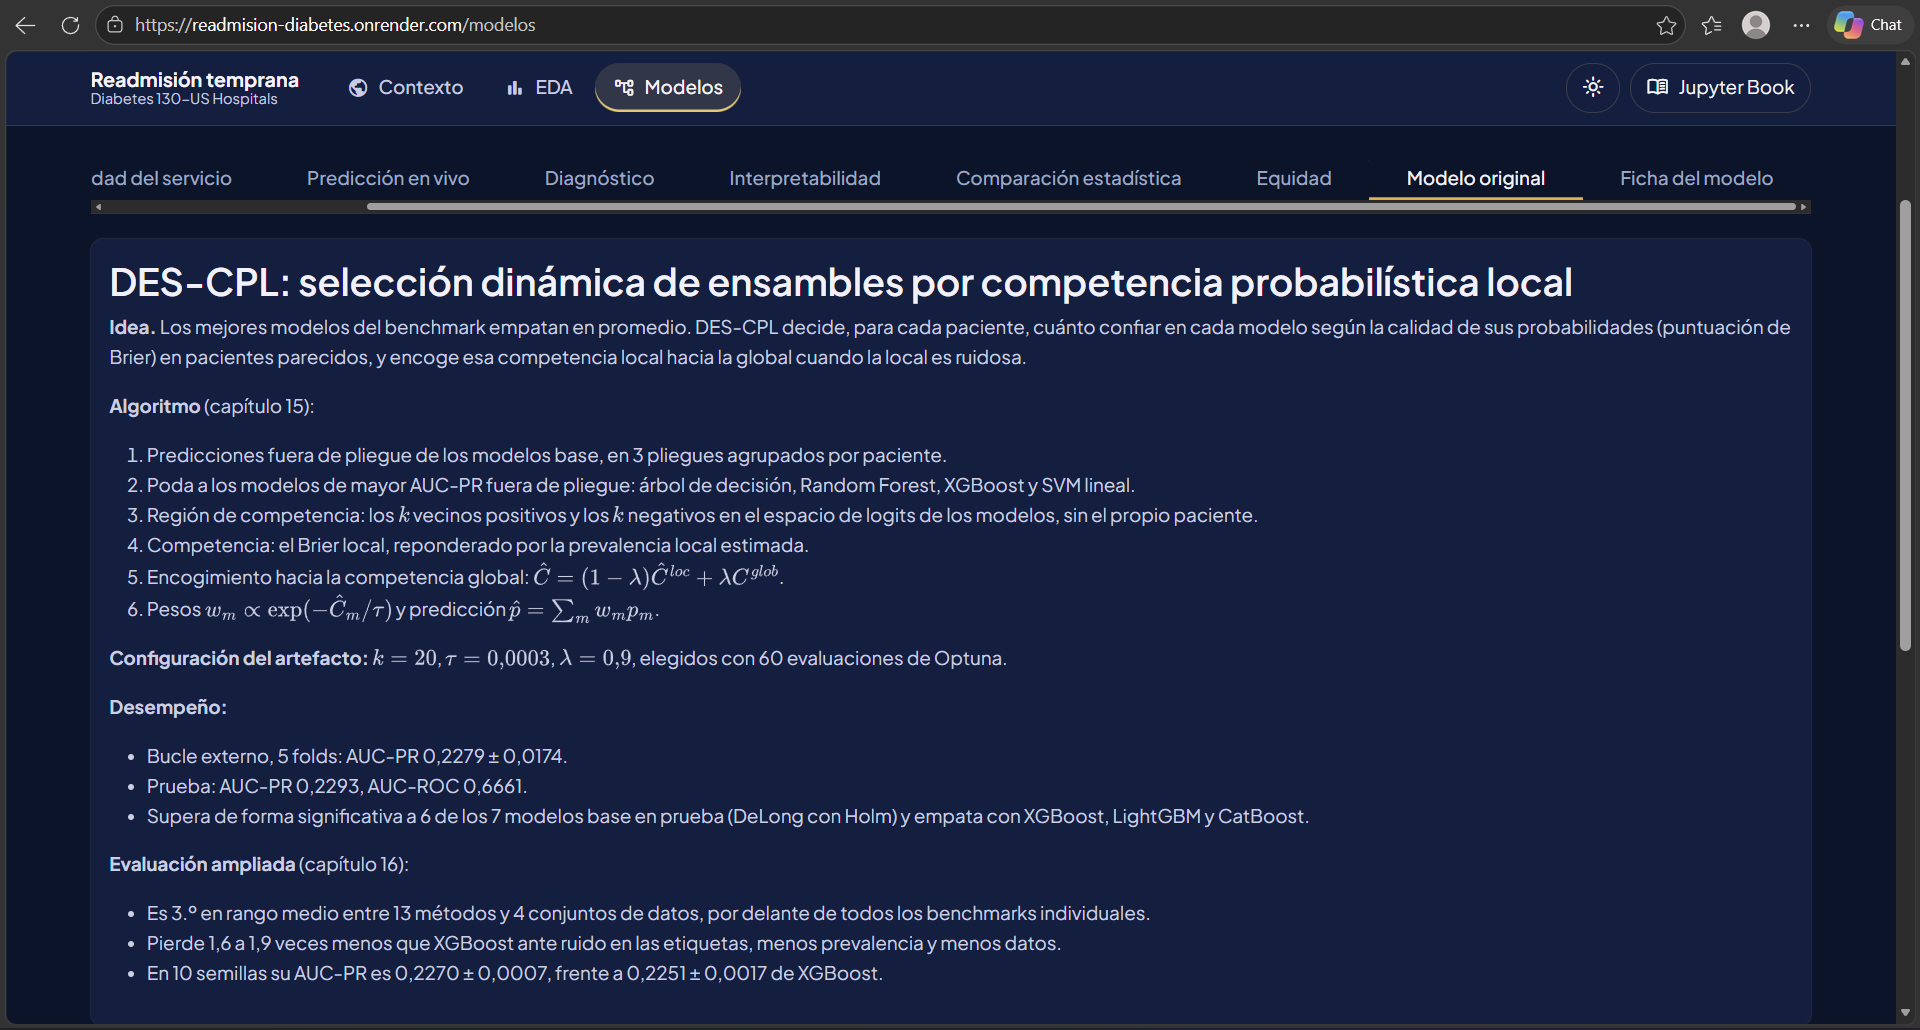

Capturas pendientes en docs/capturas/: ninguna


In [6]:
CAPTURAS = [
    ("portada.png", "Portada"),
    ("contexto.png", "Sección 1: Contexto"),
    ("eda.png", "Sección 2: EDA, con los filtros globales"),
    ("modelos_lideres.png", "Sección 3: tabla de líderes"),
    ("modelos_prediccion.png", "Sección 3: predicción en vivo con explicación local e incertidumbre"),
    ("modelos_comparacion.png", "Sección 3: comparación estadística con el modelo original"),
    ("modelos_original.png", "Sección 3: modelo original y veredicto"),
]
carpeta = RAIZ / "docs" / "capturas"
faltan = []
for archivo, titulo in CAPTURAS:
    ruta = carpeta / archivo
    if ruta.exists():
        display(Markdown(f"**{titulo}**"))
        display(Image(filename=str(ruta), width=900))
    else:
        faltan.append(archivo)
print("Capturas pendientes en docs/capturas/:", ", ".join(faltan) if faltan else "ninguna")

## 19.7. Despliegue en Render

El dashboard corre como un servicio web del plan gratuito de Render, definido en `render.yaml`:

```yaml
services:
  - type: web
    name: readmision-diabetes
    runtime: python
    plan: free
    buildCommand: pip install -r requirements-render.txt
    startCommand: gunicorn app:server --workers 1 --threads 4 --timeout 180
    envVars:
      - key: PYTHON_VERSION
        value: 3.12.13
```

**Pasos.**
1. Comprobar en local que la aplicación corre con `python app.py` y que `app.server` está expuesto.
2. Subir el repositorio a GitHub con los artefactos de `artifacts/`.
3. En Render, crear el servicio como *Blueprint* a partir de `render.yaml`.
4. Revisar los registros de la construcción y abrir la URL pública.
5. Con el despliegue automático activo, cada `push` a `main` vuelve a desplegar.

**Decisiones del despliegue.**
- **Dependencias de producción aparte.** `requirements-render.txt` lleva solo lo que el dashboard necesita, sin Jupyter Book, Optuna ni DEAP. Las librerías que reconstruyen los modelos (scikit-learn, XGBoost, imbalanced-learn, numpy, pandas, scipy y joblib) van con la **misma versión exacta** que `requirements.txt`, porque un modelo serializado solo se garantiza con la versión que lo creó.
- **Versión de Python fijada** en 3.12.13, la del entrenamiento.
- **Un problema encontrado al desplegar.** La primera versión precargaba los datos en un hilo aparte. En Render esa precarga coincidía con la primera petición y la librería que lee los archivos Parquet quedaba importada a medias en dos hilos. Se corrigió precargando en el arranque, en el hilo principal: el servidor tarda unos segundos más en iniciar, pero no hay dos importaciones simultáneas.
- **Plan gratuito.** El servicio se duerme tras un rato sin uso y la primera visita tarda cerca de un minuto en despertarlo. Conviene abrir la URL varios minutos antes de usarla.

## 19.8. Ficha del modelo

La ficha del modelo original está en `MODEL_CARD.md`, en la raíz del repositorio, y se lee desde la subpestaña «Ficha del modelo» del dashboard. Se reproduce aquí.

```{include} ../MODEL_CARD.md
:heading-offset: 2
```

## 19.9. Síntesis del capítulo

| Requisito | Cómo se cumple |
|---|---|
| Mejor combinación de cada modelo con un criterio estadístico | Mayor AUC-PR media del bucle externo; tabla con media ± desviación y motivo (sección 19.1) |
| Mejor combinación global entre los finalistas | XGBoost con ADASYN y Random Search, finalista de Friedman y Nemenyi (sección 19.1) |
| Reentrenamiento con todo el entrenamiento y serialización | Pipeline completo en `artifacts/` con `joblib` y `compress=3` (sección 19.3) |
| `metadata.json` por modelo | Versiones, semilla, hiperparámetros, esquema de entrada y métricas (sección 19.3) |
| Prueba de ida y vuelta | Aprobada en los ocho artefactos sobre todo el conjunto de prueba (sección 19.4) |
| Tamaño de los artefactos | 49 MB en total; el mayor, 30.1 MB, dentro de los límites de GitHub y de Render (sección 19.5) |
| Dashboard con Contexto, EDA y Modelos | Aplicación multipágina desplegada (sección 19.6) |
| URL pública | [https://readmision-diabetes.onrender.com](https://readmision-diabetes.onrender.com) (sección 19.7) |
| Ficha del modelo accesible desde la aplicación | `MODEL_CARD.md`, en el dashboard y en la sección 19.8 |

Una limitación queda declarada: en cuatro modelos la regla de la configuración modal no decide y el artefacto usa la configuración del primer fold (sección 19.2).

## 19.10. Autoría, uso de herramientas y archivo del repositorio

El libro se cierra con la declaración de autoría y con el archivo versionado del repositorio. Los dos están en los capítulos anteriores y se enlazan aquí:

- **Declaración de autoría y uso de herramientas, incluidas las de inteligencia artificial.** Firmada por los dos autores el 13 de noviembre de 2026, en la [sección 17.6](17_Conclusiones.ipynb).
- **Archivo versionado con identificador persistente.** DOI [10.5281/zenodo.24211425](https://doi.org/10.5281/zenodo.24211425), en la [sección 18.8](18_Reproducibilidad.ipynb).
- **Lista de verificación de reproducibilidad.** En la [sección 18.7](18_Reproducibilidad.ipynb).